# Notebook 03: Exact Models & Secondary Objectives

This notebook demonstrates the Phase 3 exact constraint programming solver (OR-Tools CP-SAT) for SALBP-1:
1. **Single Instance Exact Solve (Use Condition)**: Solve any instance with a chosen time limit and inspect status, bound, and assignment.
2. **Secondary Objectives (SO1 & SO2)**: Peak workload minimization and line smoothing on optimal station counts.
3. **Extra Station Variant ($m+1$)**: Quantifying load reduction when adding one station.
4. **Balance Population Demonstration**: Inspecting distinct candidate balances for simulation.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Ensure project src is in sys.path
project_root = Path.cwd()
if not (project_root / 'src').exists() and (project_root.parent / 'src').exists():
    project_root = project_root.parent
if str(project_root / 'src') not in sys.path:
    sys.path.insert(0, str(project_root / 'src'))

from linebench.instances.subset import load_subset_instance
from linebench.exact.cpsat_salbp1 import solve_salbp1_cpsat
from linebench.exact.secondary import solve_secondary_objective, solve_m_plus_1_min_max_load
from linebench.experiments.balances import build_balance_population_for_instance

print('Exact solver modules imported successfully!')

Exact solver modules imported successfully!


## 1. Solve an Instance with Chosen Time Limit (Use Condition)

Here we load a benchmark instance, configure solver parameters (time limit, worker threads), and inspect:
- Solver status (`OPTIMAL`, `FEASIBLE`, etc.)
- Station count $m^*$
- Theoretical lower bound vs best bound
- Station load distribution

In [2]:
# Load frozen instances config
config_path = project_root / 'configs' / 'instances.yaml'
with open(config_path, 'r', encoding='utf-8') as f:
    inst_cfg = yaml.safe_load(f)

# Pick a classical benchmark instance (e.g. Bowman-8)
entry = next(x for x in inst_cfg['benchmark_instances'] if x['id'] == 'scholl_bowman_c20')
instance = load_subset_instance(entry)
print(f'Loaded instance: {instance.name} (tasks={instance.num_tasks}, cycle_time={instance.cycle_time})')

# Solve with CP-SAT
exact_sol = solve_salbp1_cpsat(
    instance,
    time_limit_seconds=10.0,
    num_workers=2,
    random_seed=42,
    validate_with_checker=True,
)

print('\n--- CP-SAT Solution ---')
print(f'Status:            {exact_sol.status}')
print(f'Proven Optimal:    {exact_sol.is_proven_optimal}')
print(f'Stations Found:    {exact_sol.num_stations} (Published Opt: {entry.get("optimal_stations")})')
print(f'Theoretical LB:    {exact_sol.lower_bound}')
print(f'Best Bound:        {exact_sol.best_bound}')
print(f'Runtime:           {exact_sol.duration_seconds:.4f} s')
print(f'Checker Feasible:  {exact_sol.is_feasible}')

print('\nStation Assignments and Loads:')
for s, tasks in exact_sol.station_assignments.items():
    load = exact_sol.station_loads[s]
    idle = instance.cycle_time - load
    print(f'  Station {s}: tasks={tasks!s:<12} load={load:>2}/{instance.cycle_time} (idle={idle:>2})')

Loaded instance: scholl_bowman_c20 (tasks=8, cycle_time=20)

--- CP-SAT Solution ---
Status:            OPTIMAL
Proven Optimal:    True
Stations Found:    5 (Published Opt: 5)
Theoretical LB:    4
Best Bound:        5.0
Runtime:           0.0356 s
Checker Feasible:  True

Station Assignments and Loads:
  Station 1: tasks=[1]          load=11/20 (idle= 9)
  Station 2: tasks=[2]          load=17/20 (idle= 3)
  Station 3: tasks=[3]          load= 9/20 (idle=11)
  Station 4: tasks=[4, 6, 8]    load=20/20 (idle= 0)
  Station 5: tasks=[5, 7]       load=18/20 (idle= 2)


## 2. Secondary Objectives (SO1: MinMaxLoad vs SO2: Smoothness)

Once the minimum station count $m^*$ is fixed, we can re-balance the line to optimize workload characteristics:
- **SO1 (MinMaxLoad)**: Minimizes the peak workstation load $\max_s \text{load}_s$.
- **SO2 (Smoothness)**: Minimizes the sum of squared idle times $\sum_s (c - \text{load}_s)^2$.

In [3]:
m_opt = exact_sol.num_stations

# Solve SO1
so1_sol = solve_secondary_objective(
    instance,
    target_stations=m_opt,
    objective_type='SO1',
    time_limit_seconds=10.0,
)

# Solve SO2
so2_sol = solve_secondary_objective(
    instance,
    target_stations=m_opt,
    objective_type='SO2',
    time_limit_seconds=10.0,
)

# Compare
df_comp = pd.DataFrame([
    {
        'Balance': 'Arbitrary CP-SAT',
        'Stations': exact_sol.num_stations,
        'Max Load': max(exact_sol.station_loads.values()),
        'Sum Sq Idle': sum((instance.cycle_time - l)**2 for l in exact_sol.station_loads.values()),
        'Feasible': exact_sol.is_feasible,
    },
    {
        'Balance': 'SO1 (MinMaxLoad)',
        'Stations': so1_sol.target_stations,
        'Max Load': so1_sol.max_load,
        'Sum Sq Idle': so1_sol.sum_squared_idle,
        'Feasible': so1_sol.is_feasible,
    },
    {
        'Balance': 'SO2 (Smoothness)',
        'Stations': so2_sol.target_stations,
        'Max Load': so2_sol.max_load,
        'Sum Sq Idle': so2_sol.sum_squared_idle,
        'Feasible': so2_sol.is_feasible,
    },
])
df_comp

,Balance,Stations,Max Load,Sum Sq Idle,Feasible
0,Arbitrary CP-SAT,5,20,215,True
1,SO1 (MinMaxLoad),5,17,149,True
2,SO2 (Smoothness),5,17,149,True


## 3. Extra Station Variant ($m+1$)

In discrete-event simulation under variability, adding an extra workstation allows spreading the workload,
reducing the bottleneck load and line starvation/blocking.

Base optimal line (5 stations):  peak load = 17 / 20
Extra station line (6 stations): peak load = 17 / 20


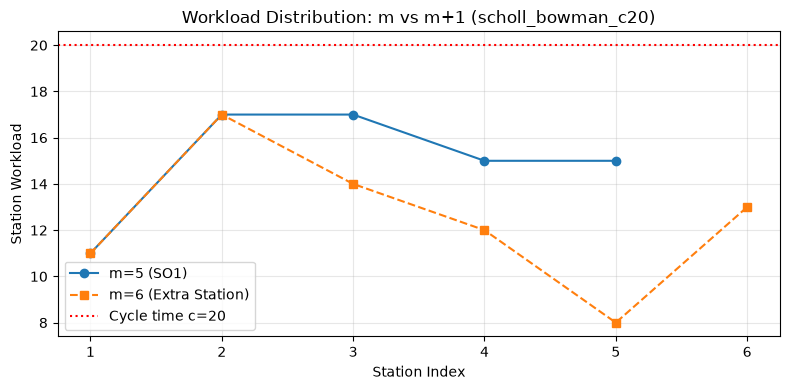

In [4]:
m_plus_1 = solve_m_plus_1_min_max_load(instance, optimal_stations=m_opt, time_limit_seconds=10.0)

print(f'Base optimal line ({m_opt} stations):  peak load = {so1_sol.max_load} / {instance.cycle_time}')
print(f'Extra station line ({m_opt + 1} stations): peak load = {m_plus_1.max_load} / {instance.cycle_time}')

# Plot comparison of station loads
fig, ax = plt.subplots(figsize=(8, 4))
stations_base = list(so1_sol.station_loads.keys())
loads_base = list(so1_sol.station_loads.values())
stations_extra = list(m_plus_1.station_loads.keys())
loads_extra = list(m_plus_1.station_loads.values())

ax.plot(stations_base, loads_base, marker='o', label=f'm={m_opt} (SO1)', color='#1f77b4')
ax.plot(stations_extra, loads_extra, marker='s', label=f'm={m_opt+1} (Extra Station)', color='#ff7f0e', linestyle='--')
ax.axhline(instance.cycle_time, color='red', linestyle=':', label=f'Cycle time c={instance.cycle_time}')
ax.set_xlabel('Station Index')
ax.set_ylabel('Station Workload')
ax.set_title(f'Workload Distribution: m vs m+1 ({instance.name})')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Full Balance Population for Simulation

Assembles the full candidate set of balances (heuristic best, exact, SO1, SO2, m+1, and distinct random balances).

In [ ]:
pop = build_balance_population_for_instance(
    instance,
    optimal_or_best_stations=m_opt,
    max_random_distinct=5,
    random_passes=200,
    solver_time_limit=10.0,
)

print(f'Total candidate balances generated: {len(pop.balances)}')
print(f'Distinct equal-station random balances: {pop.num_random_balances_found}\n')

records = []
for b in pop.balances:
    records.append({
        'Balance ID': b.balance_id,
        'Type': b.balance_type,
        'Stations': b.num_stations,
        'Max Load': b.max_load,
        'Sum Sq Idle': b.sum_squared_idle,
        'Checker Feasible': b.is_feasible,
    })
pd.DataFrame(records)